# Exercise 4.3.38 (Inpainting)

Let us consider inpainting. That is, for a vector $x_* \in \mathbb R^{N}$, we measure only entries $x_j$ for $j$ in some index set $\mathcal J \subseteq \{1, \ldots, N\}$.
This leads to the linear inverse problem $y = D x_*$, where $D$ is diagonal with elements 
$$
d_{j} = \begin{cases}
    1, & j \in \mathcal J, \\
    0, & \text{otherwise}.
\end{cases}
$$
For each pixel $j = 1,\ldots, N$, we include $j$ in $\mathcal J$ with probability $0.3$. 
As ground truth $x_*$, we use the cameraman image, available in the Python package **skimage** as **data.camera()**.
	
(i) Argue why the Tikhonov and LASSO regularization are bad choices for this problem?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

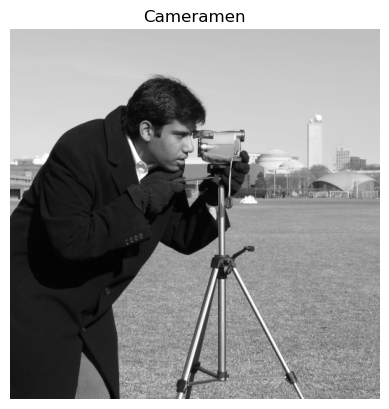

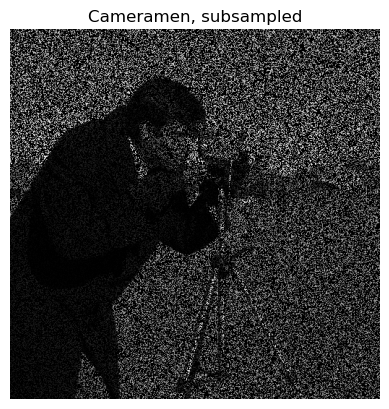

In [2]:
from skimage import data

img = data.camera()

plt.imshow(img, cmap = 'grey')
plt.title('Cameramen')
plt.axis('off')
plt.show()

mask = np.random.binomial(1, 0.3, img.shape)
meas = mask*img

plt.imshow(meas, cmap = 'grey')
plt.title('Cameramen, subsampled')
plt.axis('off')
plt.show()

(ii) Show that the discrete derivative $(\nabla x)_j = x_{j+1} - x_{j}$ from Example 4.2.9 can be implemented as convolution $\nabla x = x *_N k $ with kernel $k = e_{-1} - e_0$. See also Exercise 1.3.8. Use this observation to implement the directional derivatives
$$
(\nabla_1 \, x)_{k,j} = x_{k+1,j} - x_{k,j} 
\quad \text{and} \quad 
(\nabla_2 \, x)_{k,j} = x_{k,j+1} - x_{k,j}
$$
and their adjoints with the function **convolve(img,k, mode = 'constant')** from the Python package **ndimage**.
We use **constant** padding to account for the nonperiodic nature of $x_*$.
Test your implementation by checking that 
$$
\langle \nabla_\ell \, u, v \rangle = \langle u, \nabla_\ell^T \, v \rangle, \quad \ell = 1,2
$$
for random $u$ and $v$.  

-1.1368683772161603e-13
-4.547473508864641e-13


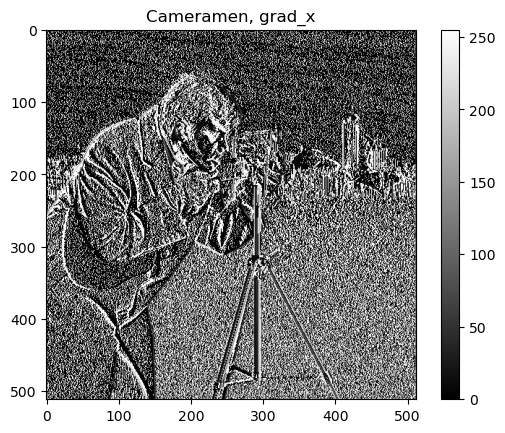

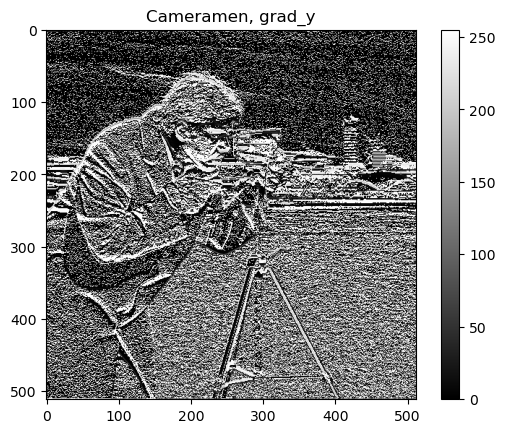

In [3]:
from scipy import ndimage

kx = np.array([ [0,0,0], [1,-1,0], [0,0,0] ])
kx_adj = np.array([ [0,0,0], [0,-1,1], [0,0,0] ])

grad_x = lambda img: ndimage.convolve(img,kx, mode = 'constant')
grad_x_adj = lambda img: ndimage.convolve(img,kx_adj, mode = 'constant')

grad_y = lambda img: ndimage.convolve(img,kx.T, mode = 'constant')
grad_y_adj = lambda img: ndimage.convolve(img,kx_adj.T, mode = 'constant')


t1 = np.random.randn(img.shape[0],img.shape[1])
t2 = np.random.randn(img.shape[0],img.shape[1])

print(np.sum(grad_x(t1) * t2) - np.sum(t1 * grad_x_adj(t2)))
print(np.sum(grad_y(t1) * t2) - np.sum(t1 * grad_y_adj(t2)))

plt.imshow(np.abs(grad_x(img)), cmap = 'grey')
plt.title('Cameramen, grad_x')
plt.colorbar()
plt.show()

plt.imshow(np.abs(grad_y(img)), cmap = 'grey')
plt.title('Cameramen, grad_y')
plt.colorbar()
plt.show()

(iii) Implement accelerated gradient descent (Algorithm 2) for the variational reconstruction objective with the smoothness prior from Example 4.2.9, namely
$$
J_\alpha(x) = \|Dx - y\|^2_2 + \alpha (\| \nabla_1 x\|^2_2 + \| \nabla_2 x \|^2_2).
$$
Visualize the reconstruction for $\alpha = 0.1$.  

In [4]:
def fast_FBS(x0, nu, grad, prox, loss, num_iter, it_thr = 0, xt = None):
    x = x0
    func_val = np.zeros((num_iter + 1))
    func_val[0] = loss(x0) 
    z = x0
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        x_old = x
        theta = 2.0/(2 + k)
        u = (1 - theta)*x + theta*z
        x = prox(u - nu* grad(u), nu)
        z = x_old + (x - x_old) / theta
        
        func_val[k+1] = loss(x)
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
        
        if it_thr > 0 and np.linalg.norm(x - x_old) < it_thr:
            break
                
    if xt is not None:
        return x, func_val, error
    else:
        return x, func_val

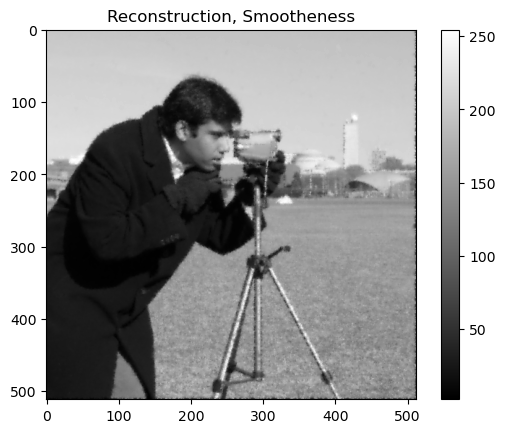

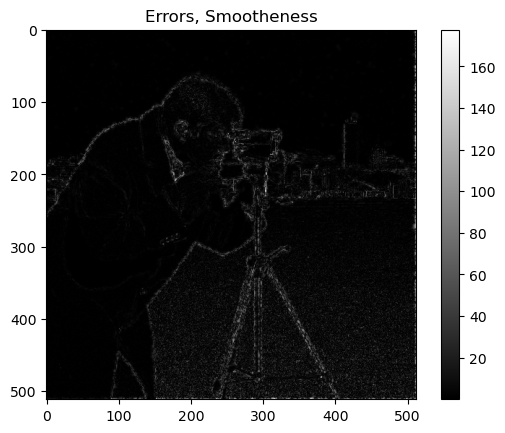

In [5]:
conv_ker = np.zeros((img.shape[0]))
conv_ker[1] = 1
conv_ker[0] = -1
spec = np.max(np.abs(np.fft.fft(conv_ker)))

num_iter = 100

alpha = 0.1
# Smoothness

grad = lambda img: mask * ( mask * img - meas) + alpha *(grad_x_adj(grad_x(img)) + grad_y_adj(grad_y(img)))
loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*alpha * (np.linalg.norm(grad_x(img))**2 + np.linalg.norm(grad_y(img))**2)
prox = lambda img,nu: img
nu = 1.0 / (1  + 2*alpha* spec**2)

x1, m_errors, errors = fast_FBS(meas, nu, grad, prox, loss,num_iter, 1e-8, img)

plt.imshow(x1, cmap = 'grey')
plt.title('Reconstruction, Smootheness')
plt.colorbar()
plt.show()

plt.imshow(np.abs(x1 - img), cmap = 'grey')
plt.title('Errors, Smootheness')
plt.colorbar()
plt.show()

(iv) Now, we want to use the TV regularization from Example 4.2.11, namely
$$
J_\alpha(x) = \|Dx - y\|^2_2 + \alpha (\| \nabla_1 x\|_1 + \| \nabla_2 x \|_1). \qquad (4.123)
$$
Based on Example 4.3.35 and Remark 4.3.26, implement the ADMM with $\gamma = 1$ to minimize (4.123) with $\alpha = 1$.
For the least squares sub-iteration, use the conjugate gradient method (or your implementation of gradient descent) with $10$ iterations and initialization $x_t$ from the previous ADMM iteration. 
Why are 10 iterations sufficient?

In [6]:
def ADMM_TV(x0, alpha, gamma, mask, meas, num_iter, num_subit, verbose = False,xt = None):
    z1 = grad_x(x0)
    z2 = grad_y(x0)
    b1 = np.zeros_like(z1)
    b2 = np.zeros_like(z2)
    x = x0
    soft_tr = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alpha, 0)
    loss_ADMM = lambda x: 0.5*np.linalg.norm(mask * x - meas )**2 + alpha * (np.sum(np.abs(grad_x(x))) + np.sum(np.abs(grad_y(x))))
    # baseline = loss_ADMM(np.zeros_like(x0))

    f_value = np.zeros((num_iter + 1))
    f_value[0] = loss_ADMM(x0)

    constr_er = np.zeros((num_iter + 1))
    constr_er[0] = np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
    
    for ik in range(num_iter):
        
        # update x
        grad = lambda img: mask * ( mask * img - meas) + 0.5*gamma *(grad_x_adj(grad_x(img) - (z1 - b1)) + grad_y_adj(grad_y(img) - (z2 - b2)))
        loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*gamma * (np.linalg.norm(grad_x(img) - (z1 - b1))**2 + np.linalg.norm(grad_y(img) - (z2 - b2))**2)
        prox_id = lambda img,nu: img
        nu = 1.0 / (1  + gamma * spec**2)
        x, er = fast_FBS(x, nu, grad, prox_id, loss,num_subit, 1e-8)

        f_value[ik+1] = loss_ADMM(x)
        
        if xt is not None:
            error[ik+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        constr_er[ik+1] = np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2

        if verbose:
            if xt is not None:
                print(f"Iteration: {ik} F: {f_value[ik+1]:.1f} Const. error: {constr_er[ik+1]:.1f} Rel. Error: {error[ik+1]:.5f}")
            else:
                print(f"Iteration: {ik} F: {f_value[ik+1]:.1f} Const. error: {constr_er[ik+1]:.1f}")
            
        # update z
        z1 = soft_tr(b1 + grad_x(x),alpha / gamma)
        z2 = soft_tr(b2 + grad_y(x),alpha / gamma)

        # update b
        b1 = b1 + grad_x(x) - z1
        b2 = b2 + grad_y(x) - z2

    if xt is not None:
        return x, constr_er, error
    else:
        return x, constr_er,

In [7]:
num_iter = 500
num_subit = 10

img_rec, constr_er, errors = ADMM_TV(x0 = meas, 
                                               alpha = 1e0,
                                               gamma= 1e0, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 F: 28626046.0 Const. error: 0.0 Rel. Error: 0.83709
Iteration: 1 F: 28261848.7 Const. error: 154271.6 Rel. Error: 0.83133
Iteration: 2 F: 28070969.2 Const. error: 144832.4 Rel. Error: 0.82710
Iteration: 3 F: 27890303.1 Const. error: 145989.1 Rel. Error: 0.82309
Iteration: 4 F: 27712008.7 Const. error: 145424.1 Rel. Error: 0.81912
Iteration: 5 F: 27536905.3 Const. error: 144324.9 Rel. Error: 0.81519
Iteration: 6 F: 27363363.3 Const. error: 142837.1 Rel. Error: 0.81127
Iteration: 7 F: 27191096.0 Const. error: 141487.0 Rel. Error: 0.80737
Iteration: 8 F: 27020407.9 Const. error: 140430.1 Rel. Error: 0.80349
Iteration: 9 F: 26850956.0 Const. error: 139559.6 Rel. Error: 0.79961
Iteration: 10 F: 26682606.6 Const. error: 138809.8 Rel. Error: 0.79575
Iteration: 11 F: 26515219.0 Const. error: 138095.2 Rel. Error: 0.79190
Iteration: 12 F: 26348576.0 Const. error: 137411.1 Rel. Error: 0.78805
Iteration: 13 F: 26182670.3 Const. error: 136790.3 Rel. Error: 0.78422
Iteration: 14 F: 2601

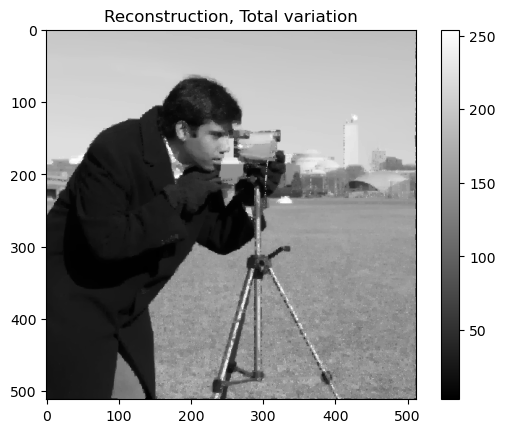

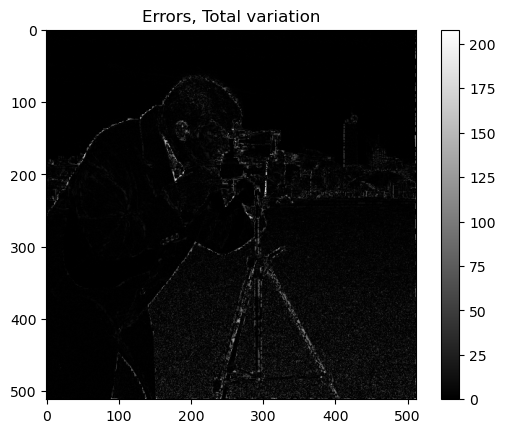

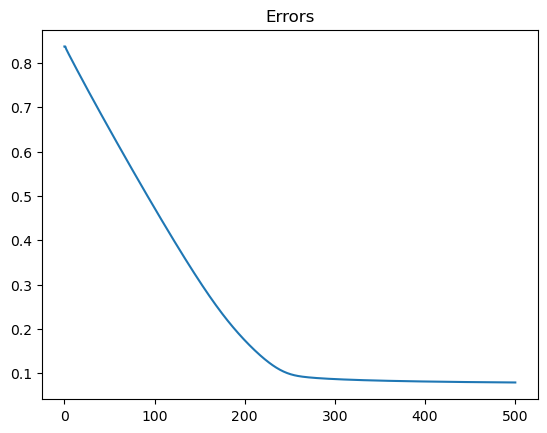

In [8]:
plt.imshow(img_rec, cmap = 'grey')
plt.title('Reconstruction, Total Variation')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec - img), cmap = 'grey')
plt.title('Errors, Total Variation')
plt.colorbar()
plt.show()

plt.plot(errors)
plt.title('Errors')
plt.show()

(v) Plot the absolute errors $| D(x - x_*)|$. For inpainting, we want to enforce that the error on the measured pixels is zero. This is done via the functional
$$
J(x) = \iota_{ \{z \colon Dz = y\}}(x) + \| \nabla_1 x\|_1 + \| \nabla_2 x \|_1, \qquad (4.124)
$$
where 
$$
    \iota_{\mathcal S}(x) = \begin{cases}
    0, & x \in \mathcal S,\\
    \infty, & x \notin \mathcal S.
\end{cases}
$$
Implement ADMM with $\gamma = 0.01$ for minimizing (4.124) and perform the reconstruction.
Plot the absolute errors $| D(x - x_*) |$ again and explain the difference.



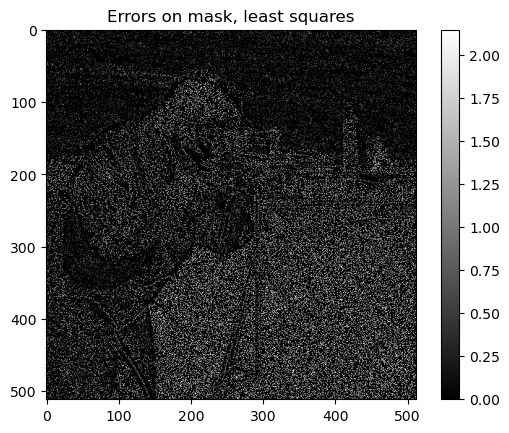

In [9]:
plt.imshow(np.abs(img_rec - img)*mask, cmap = 'grey')
plt.title('Errors on mask, least squares')
plt.colorbar()
plt.show()

In [10]:
def ADMM_inpainting_TV(x0, gamma, mask, meas, num_iter, num_subit, verbose = False,xt = None):
    z1 = grad_x(x0)
    z2 = grad_y(x0)
    b0 = mask * x0 - meas
    b1 = np.zeros_like(z1)
    b2 = np.zeros_like(z2)
    x = x0
    prox = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alpha, 0)
    
    constr_er = np.zeros((num_iter + 1))
    constr_er[0] = np.linalg.norm(mask*x - meas)**2 + np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
    
    for ik in range(num_iter):
        
        # update x
        grad = lambda img: 0.5*gamma *( mask * ( mask * img - (meas - b0)) + grad_x_adj(grad_x(img) - (z1 - b1)) + grad_y_adj(grad_y(img) - (z2 - b2)))
        loss = lambda img: 0.5*np.linalg.norm(mask * img - (meas + b0) )**2 + 0.5*gamma * (np.linalg.norm(grad_x(img) - (z1 - b1))**2 + np.linalg.norm(grad_y(img) - (z2 - b2))**2)
        prox_id = lambda img,nu: img
        nu = 1.0 / (gamma * (0.5  +  spec**2))
        x, er = fast_FBS(x, nu, grad, prox_id, loss,num_subit, 1e-8)
        
        if xt is not None:
            # print(xt.shape)
            # print(x.shape)
            # print(np.linalg.norm(x-xt))
            error[ik+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        constr_er[ik+1] = np.linalg.norm(mask*x - meas)**2 + np.linalg.norm(grad_x(x) - z1)**2 + np.linalg.norm(grad_y(x) - z2)**2

        if verbose:
            if xt is not None:
                print(f"Iteration: {ik} Const. error: {constr_er[ik+1]:.1f} Rel. Error: {error[ik+1]:.5f}")
            else:
                print(f"Iteration: {ik} Const. error: {constr_er[ik+1]:.1f}")
            
        # update z
        z1 = prox(b1 + grad_x(x),1.0 / gamma)
        z2 = prox(b2 + grad_y(x),1.0 / gamma)

        # update b
        b0 = b0 + mask * x - meas
        b1 = b1 + grad_x(x) - z1
        b2 = b2 + grad_y(x) - z2

    if xt is not None:
        return x, constr_er, error
    else:
        return x, constr_er,

In [11]:
num_iter = 500
num_subit = 10

img_rec_in, constr_er, errors = ADMM_inpainting_TV(x0 = meas, 
                                               gamma= 1e-2, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 Const. error: 0.0 Rel. Error: 0.83709
Iteration: 1 Const. error: 19570910.1 Rel. Error: 0.78887
Iteration: 2 Const. error: 13028211.9 Rel. Error: 0.73882
Iteration: 3 Const. error: 11366196.8 Rel. Error: 0.68975
Iteration: 4 Const. error: 11388204.7 Rel. Error: 0.64655
Iteration: 5 Const. error: 11734221.1 Rel. Error: 0.60879
Iteration: 6 Const. error: 11608549.5 Rel. Error: 0.57412
Iteration: 7 Const. error: 11207806.2 Rel. Error: 0.54043
Iteration: 8 Const. error: 10806529.6 Rel. Error: 0.50653
Iteration: 9 Const. error: 10463036.4 Rel. Error: 0.47212
Iteration: 10 Const. error: 10180852.2 Rel. Error: 0.43747
Iteration: 11 Const. error: 9976789.1 Rel. Error: 0.40306
Iteration: 12 Const. error: 9836670.7 Rel. Error: 0.36930
Iteration: 13 Const. error: 9731684.7 Rel. Error: 0.33644
Iteration: 14 Const. error: 9622231.9 Rel. Error: 0.30465
Iteration: 15 Const. error: 9470566.5 Rel. Error: 0.27411
Iteration: 16 Const. error: 9236941.5 Rel. Error: 0.24509
Iteration: 17 Const.

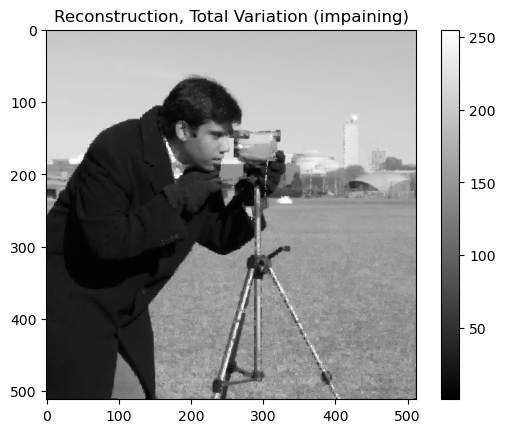

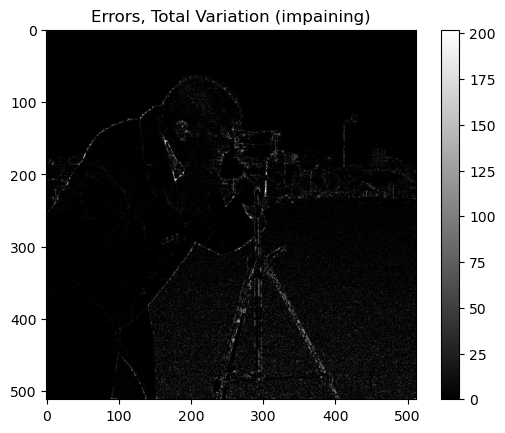

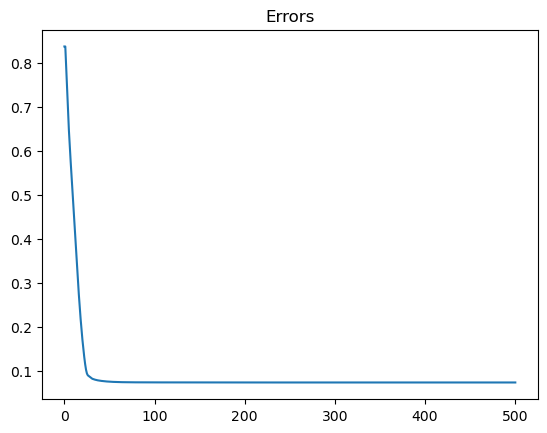

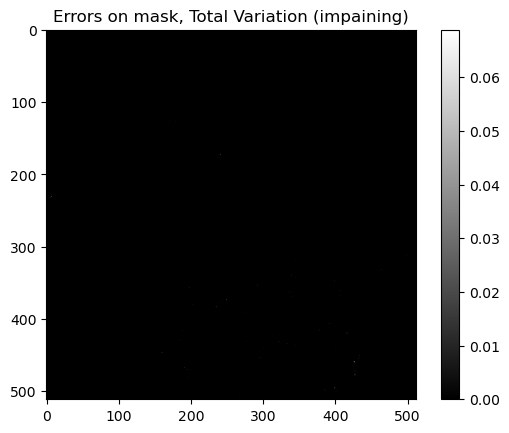

In [12]:
plt.imshow(img_rec_in, cmap = 'grey')
plt.title('Reconstruction, Total Variation (impaining)')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_in - img), cmap = 'grey')
plt.title('Errors, Total Variation (impaining)')
plt.colorbar()
plt.show()

plt.plot(errors)
plt.title('Errors')
plt.show()

plt.imshow(np.abs(img_rec_in - img)*mask, cmap = 'grey')
plt.title('Errors on mask, Total Variation (impaining)')
plt.colorbar()
plt.show()

(vi) Now, we change the sampling of $\mathcal J$.
Instead of random  pixels, we exclude a $50 \times 50$ box that contains the cameraman's face.
Try to reconstruct it with the algorithms from above and explain the outcome.

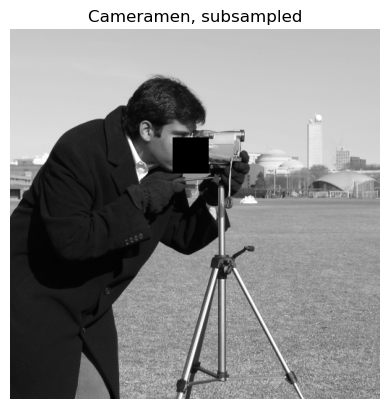

In [13]:
mask = np.ones_like(img)
mask[150:200,225:275] = 0

meas = mask * img

plt.imshow(meas, cmap = 'grey')
plt.title('Cameramen, subsampled')
plt.axis('off')
plt.show()

In [14]:
num_iter = 100
alpha = 0.1

# Smoothness

grad = lambda img: mask * ( mask * img - meas) + alpha *(grad_x_adj(grad_x(img)) + grad_y_adj(grad_y(img)))
loss = lambda img: 0.5*np.linalg.norm(mask * img - meas )**2 + 0.5*alpha * (np.linalg.norm(grad_x(img))**2 + np.linalg.norm(grad_y(img))**2)
prox = lambda img,nu: img
nu = 1.0 / (1  + 2*alpha* spec**2)

x1, m_errors, errors = fast_FBS(meas, nu, grad, prox, loss,num_iter, 1e-8, img)

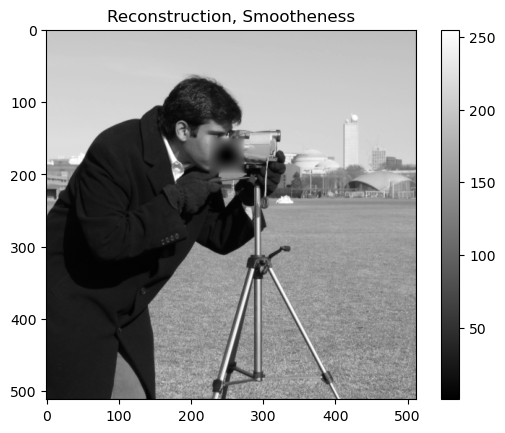

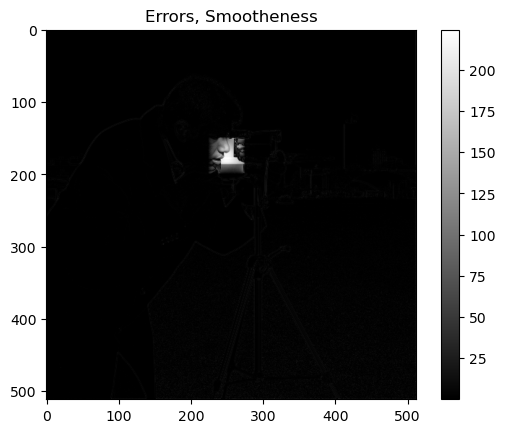

In [15]:
plt.imshow(x1, cmap = 'grey')
plt.title('Reconstruction, Smootheness')
plt.colorbar()
plt.show()

plt.imshow(np.abs(x1 - img), cmap = 'grey')
plt.title('Errors, Smootheness')
plt.colorbar()
plt.show()

In [16]:
# ADMM TV
num_iter = 500
num_subit = 10

img_rec_face, constr_er_face, errors_face = ADMM_TV(x0 = meas, 
                                       alpha = 1e+0,
                                       gamma= 1e0, 
                                       mask = mask, 
                                       meas = meas, 
                                       num_iter = num_iter, 
                                       num_subit = num_subit, 
                                       verbose = True,
                                       xt = img)

Iteration: 0 F: 331367048.9 Const. error: 8126011224.5 Rel. Error: 0.34072
Iteration: 1 F: 127467488.4 Const. error: 265890150.7 Rel. Error: 0.22067
Iteration: 2 F: 60226706.2 Const. error: 101689879.4 Rel. Error: 0.16504
Iteration: 3 F: 30929699.4 Const. error: 45384893.4 Rel. Error: 0.13497
Iteration: 4 F: 17055051.2 Const. error: 21680312.7 Rel. Error: 0.11882
Iteration: 5 F: 10206406.3 Const. error: 10765299.2 Rel. Error: 0.11034
Iteration: 6 F: 6732074.0 Const. error: 5496391.2 Rel. Error: 0.10597
Iteration: 7 F: 4933000.4 Const. error: 2863506.9 Rel. Error: 0.10372
Iteration: 8 F: 3998141.2 Const. error: 1513741.3 Rel. Error: 0.10256
Iteration: 9 F: 3528604.2 Const. error: 804649.5 Rel. Error: 0.10194
Iteration: 10 F: 3326990.0 Const. error: 421709.5 Rel. Error: 0.10160
Iteration: 11 F: 3259756.7 Const. error: 206361.2 Rel. Error: 0.10139
Iteration: 12 F: 3234728.2 Const. error: 89045.3 Rel. Error: 0.10124
Iteration: 13 F: 3222009.9 Const. error: 35226.1 Rel. Error: 0.10111
Itera

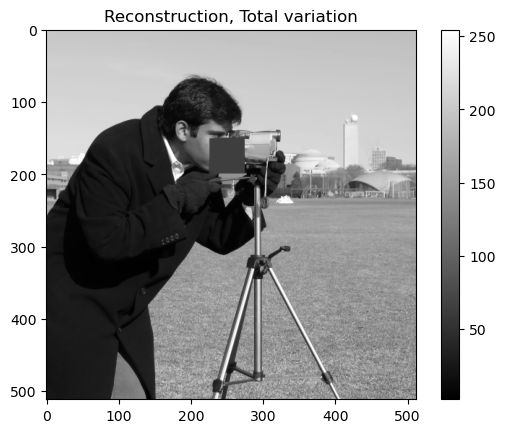

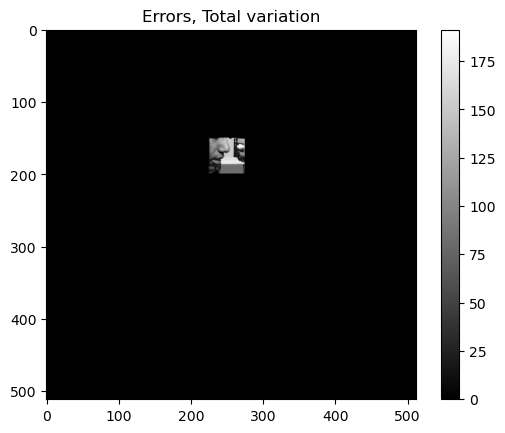

In [17]:
plt.imshow(img_rec_face, cmap = 'grey')
plt.title('Reconstruction, Total Variation')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_face - img), cmap = 'grey')
plt.title('Errors, Total Variation')
plt.colorbar()
plt.show()

In [18]:
# ADMM impaining
img_rec_im_face, constr_er_im_face, errors_im_face = ADMM_inpainting_TV(x0 = meas, 
                                               gamma= 1e-2, 
                                               mask = mask, 
                                               meas = meas, 
                                               num_iter = num_iter, 
                                               num_subit = num_subit, 
                                               verbose = True,
                                               xt = img)

Iteration: 0 Const. error: 8576985007.6 Rel. Error: 0.42962
Iteration: 1 Const. error: 1076063212.4 Rel. Error: 0.20426
Iteration: 2 Const. error: 677154614.8 Rel. Error: 0.14148
Iteration: 3 Const. error: 349341083.2 Rel. Error: 0.13783
Iteration: 4 Const. error: 128079465.5 Rel. Error: 0.13809
Iteration: 5 Const. error: 85525147.4 Rel. Error: 0.14142
Iteration: 6 Const. error: 63740877.0 Rel. Error: 0.13432
Iteration: 7 Const. error: 49182409.1 Rel. Error: 0.12137
Iteration: 8 Const. error: 38368988.5 Rel. Error: 0.10847
Iteration: 9 Const. error: 29882134.8 Rel. Error: 0.09994
Iteration: 10 Const. error: 22427121.3 Rel. Error: 0.09628
Iteration: 11 Const. error: 14961617.8 Rel. Error: 0.09494
Iteration: 12 Const. error: 8684274.2 Rel. Error: 0.09388
Iteration: 13 Const. error: 5191413.8 Rel. Error: 0.09250
Iteration: 14 Const. error: 3665555.9 Rel. Error: 0.09089
Iteration: 15 Const. error: 2782392.2 Rel. Error: 0.08920
Iteration: 16 Const. error: 2186545.9 Rel. Error: 0.08768
Itera

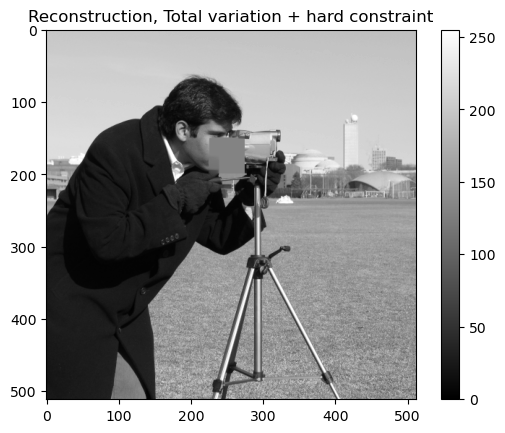

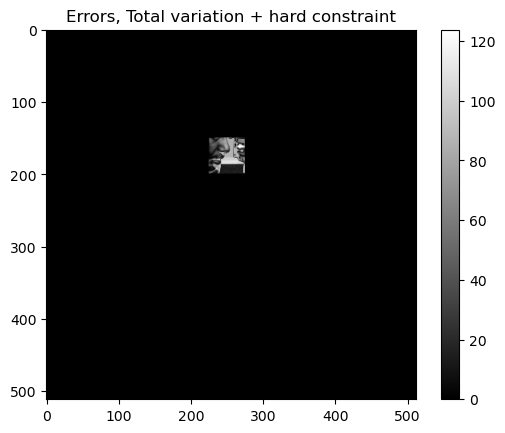

In [19]:
plt.imshow(img_rec_im_face, cmap = 'grey')
plt.title('Reconstruction, Total Variation (impainting)')
plt.colorbar()
plt.show()

plt.imshow(np.abs(img_rec_im_face - img), cmap = 'grey')
plt.title('Errors, Total Variation (impainting)')
plt.colorbar()
plt.show()